In [3]:
!git clone https://github.com/jasmindamia/UTP-MACHINE-LEARNING.git /content/UTP-MACHINE-LEARNING

Cloning into '/content/UTP-MACHINE-LEARNING'...
remote: Enumerating objects: 45, done.
remote: Counting objects: 100% (45/45), done.
remote: Compressing objects: 100% (40/40), done.
remote: Total 45 (delta 13), reused 24 (delta 3), pack-reused 0 (from 0)
Receiving objects: 100% (45/45), 2.30 MiB | 9.90 MiB/s, done.
Resolving deltas: 100% (13/13), done.


In [4]:
from pathlib import Path

PROJECT_ROOT = Path("/content/UTP-MACHINE-LEARNING")
DATA = PROJECT_ROOT / "all_datasets"
MODELS = PROJECT_ROOT / "models"

MODELS.mkdir(parents=True, exist_ok=True)

print("Repository exists:", PROJECT_ROOT.exists())
print("Dataset folder exists:", DATA.exists())
print("Models folder exists:", MODELS.exists())

print("\nAvailable datasets:")
if DATA.exists():
    for file in sorted(DATA.iterdir()):
        print(file.name)
else:
    print("Dataset folder not found. We'll locate the datasets next.")

print("\nAvailable experiment notebooks:")
for file in sorted((PROJECT_ROOT / "all_experiments").glob("*.ipynb")):
    print(file.name)

Repository exists: True
Dataset folder exists: True
Models folder exists: True

Available datasets:
ames_housing_dataset.csv
bike_sharing_dataset_day.csv
bike_sharing_dataset_hour.csv
breast_cancer_dataset.csv
credit_card_fraud_dataset.csv
heart_failure_dataset.csv
mall_customers_dataset.csv
medical_cost_personal_dataset.csv
optical_recognition_handwritten_digits.zip
red_wine_quality_dataset.csv
student_performance_dataset.csv
titanic_dataset.csv

Available experiment notebooks:
Lab01_feature_engineering.ipynb
Lab02_supervised_learning.ipynb
lab03_model_families.ipynb


In [5]:
import zipfile
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, silhouette_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

PROJECT_ROOT = Path("/content/UTP-MACHINE-LEARNING")
DATA = PROJECT_ROOT / "all_datasets"
MODELS = PROJECT_ROOT / "models"
MODELS.mkdir(parents=True, exist_ok=True)

print("Setup complete!")
print("Dataset folder:", DATA)
print("Model folder:", MODELS)

Setup complete!
Dataset folder: /content/UTP-MACHINE-LEARNING/all_datasets
Model folder: /content/UTP-MACHINE-LEARNING/models


In [6]:
# Load the mall customers dataset
df = pd.read_csv(DATA / "mall_customers_dataset.csv")

# Inspect the dataset
print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (200, 5)

First 5 rows:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



Column names:
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Missing values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


In [7]:
# Select numerical features for clustering
features = [
    "Age",
    "Annual Income (k$)",
    "Spending Score (1-100)"
]

X = df[features].copy()

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Selected features:", features)
print("Original data shape:", X.shape)
print("Standardized data shape:", X_scaled.shape)

print("\nStandardized feature means:")
print(X_scaled.mean(axis=0).round(3))

print("\nStandardized feature standard deviations:")
print(X_scaled.std(axis=0).round(3))

Selected features: ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
Original data shape: (200, 3)
Standardized data shape: (200, 3)

Standardized feature means:
[-0. -0. -0.]

Standardized feature standard deviations:
[1. 1. 1.]


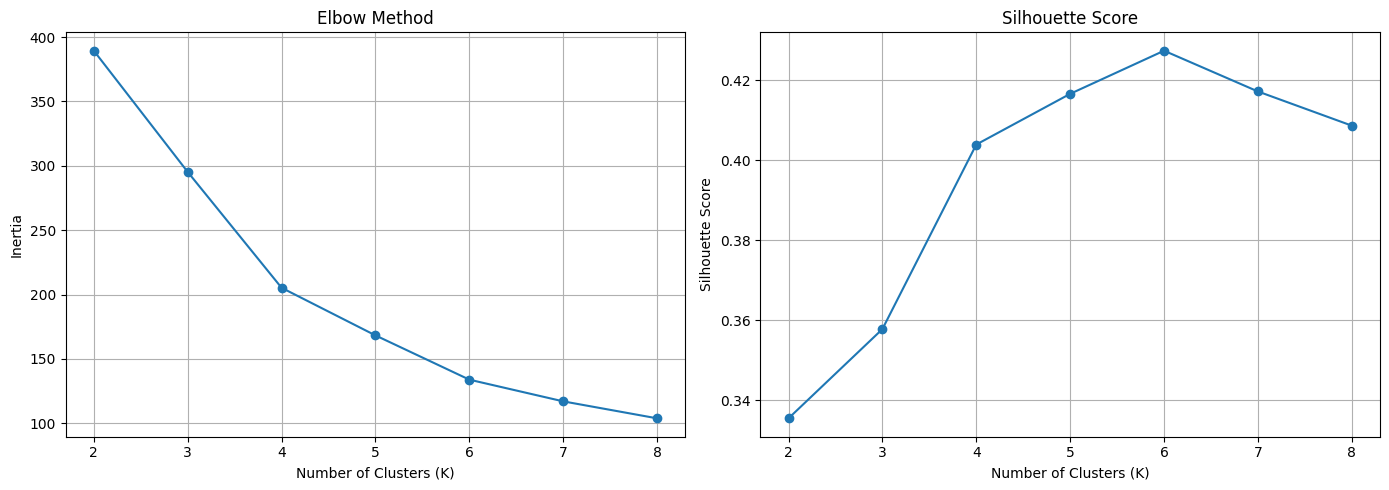

,K,Inertia,Silhouette Score
0,2,389.386,0.335
1,3,295.212,0.358
2,4,205.225,0.404
3,5,168.248,0.417
4,6,133.868,0.427
5,7,117.012,0.417
6,8,103.829,0.409


In [8]:
# Test K values from 2 to 8
k_values = range(2, 9)

inertia_scores = []
silhouette_scores = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        n_init=20,
        random_state=42
    )

    labels = kmeans.fit_predict(X_scaled)

    inertia_scores.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

# Plot elbow method and silhouette scores
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(list(k_values), inertia_scores, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")
axes[0].set_xticks(list(k_values))
axes[0].grid(True)

axes[1].plot(list(k_values), silhouette_scores, marker="o")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_xticks(list(k_values))
axes[1].grid(True)

plt.tight_layout()
plt.show()

# Display the scores
results = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertia_scores,
    "Silhouette Score": silhouette_scores
})

display(results.round(3))

In [9]:
# Fit the final K-Means model
kmeans = KMeans(
    n_clusters=5,
    n_init=30,
    random_state=42
)

df["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)

print("Customers assigned:", df["KMeans_Cluster"].notna().sum())
print("\nCustomers per cluster:")
print(df["KMeans_Cluster"].value_counts().sort_index())

# Summarize each cluster using the original feature values
cluster_profile = df.groupby("KMeans_Cluster").agg(
    Customer_Count=("CustomerID", "count"),
    Average_Age=("Age", "mean"),
    Average_Income=("Annual Income (k$)", "mean"),
    Average_Spending_Score=("Spending Score (1-100)", "mean")
).round(2)

print("\nCustomer profiles:")
display(cluster_profile)


Customers assigned: 200

Customers per cluster:
KMeans_Cluster
0    20
1    54
2    40
3    39
4    47
Name: count, dtype: int64

Customer profiles:


,Customer_Count,Average_Age,Average_Income,Average_Spending_Score
KMeans_Cluster,,,,
0,20,46.25,26.75,18.35
1,54,25.19,41.09,62.24
2,40,32.88,86.10,81.53
3,39,39.87,86.10,19.36
4,47,55.64,54.38,48.85


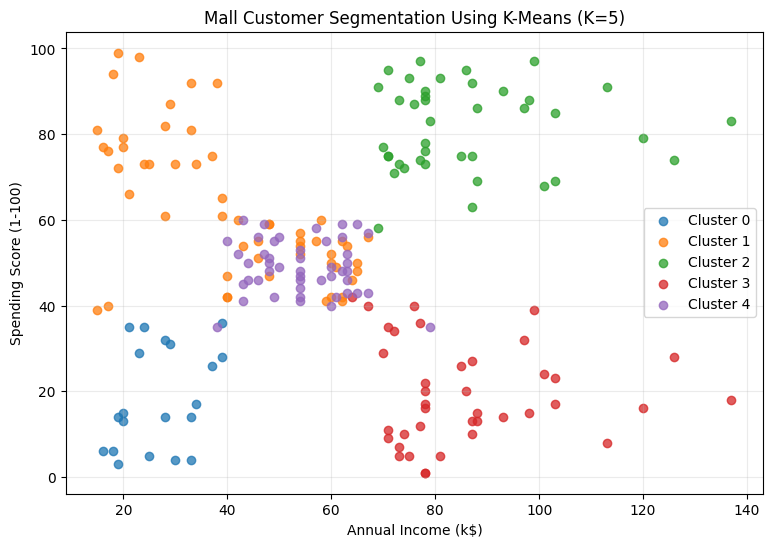

In [10]:
# Plot K-Means customer clusters
plt.figure(figsize=(9, 6))

for cluster in sorted(df["KMeans_Cluster"].unique()):
    cluster_data = df[df["KMeans_Cluster"] == cluster]

    plt.scatter(
        cluster_data["Annual Income (k$)"],
        cluster_data["Spending Score (1-100)"],
        label=f"Cluster {cluster}",
        alpha=0.75
    )

plt.title("Mall Customer Segmentation Using K-Means (K=5)")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

In [11]:
# Fit DBSCAN
dbscan = DBSCAN(
    eps=0.75,
    min_samples=6
)

df["DBSCAN_Cluster"] = dbscan.fit_predict(X_scaled)

# Count clusters and noise points
dbscan_labels = df["DBSCAN_Cluster"]
n_clusters = len(set(dbscan_labels) - {-1})
n_noise = (dbscan_labels == -1).sum()

print("DBSCAN parameters: eps=0.75, min_samples=6")
print("Number of clusters:", n_clusters)
print("Number of noise points:", n_noise)

print("\nPoints per label (-1 means noise):")
print(dbscan_labels.value_counts().sort_index())

# Calculate silhouette score for non-noise points, if valid
non_noise_mask = dbscan_labels != -1
non_noise_labels = dbscan_labels[non_noise_mask]
n_non_noise_clusters = len(set(non_noise_labels))

if 2 <= n_non_noise_clusters < len(non_noise_labels):
    score = silhouette_score(
        X_scaled[non_noise_mask],
        non_noise_labels
    )
    print("\nSilhouette score (excluding noise):", round(score, 3))
else:
    print("\nSilhouette score not meaningful for this result.")

DBSCAN parameters: eps=0.75, min_samples=6
Number of clusters: 1
Number of noise points: 14

Points per label (-1 means noise):
DBSCAN_Cluster
-1     14
 0    186
Name: count, dtype: int64

Silhouette score not meaningful for this result.


In [12]:
# Try a smaller DBSCAN radius
dbscan_small = DBSCAN(
    eps=0.5,
    min_samples=6
)

df["DBSCAN_eps_05"] = dbscan_small.fit_predict(X_scaled)

labels_small = df["DBSCAN_eps_05"]
n_clusters_small = len(set(labels_small) - {-1})
n_noise_small = (labels_small == -1).sum()

print("DBSCAN parameters: eps=0.5, min_samples=6")
print("Number of clusters:", n_clusters_small)
print("Number of noise points:", n_noise_small)

print("\nPoints per label (-1 means noise):")
print(labels_small.value_counts().sort_index())

DBSCAN parameters: eps=0.5, min_samples=6
Number of clusters: 5
Number of noise points: 66

Points per label (-1 means noise):
DBSCAN_eps_05
-1    66
 0    16
 1    50
 2    29
 3    32
 4     7
Name: count, dtype: int64


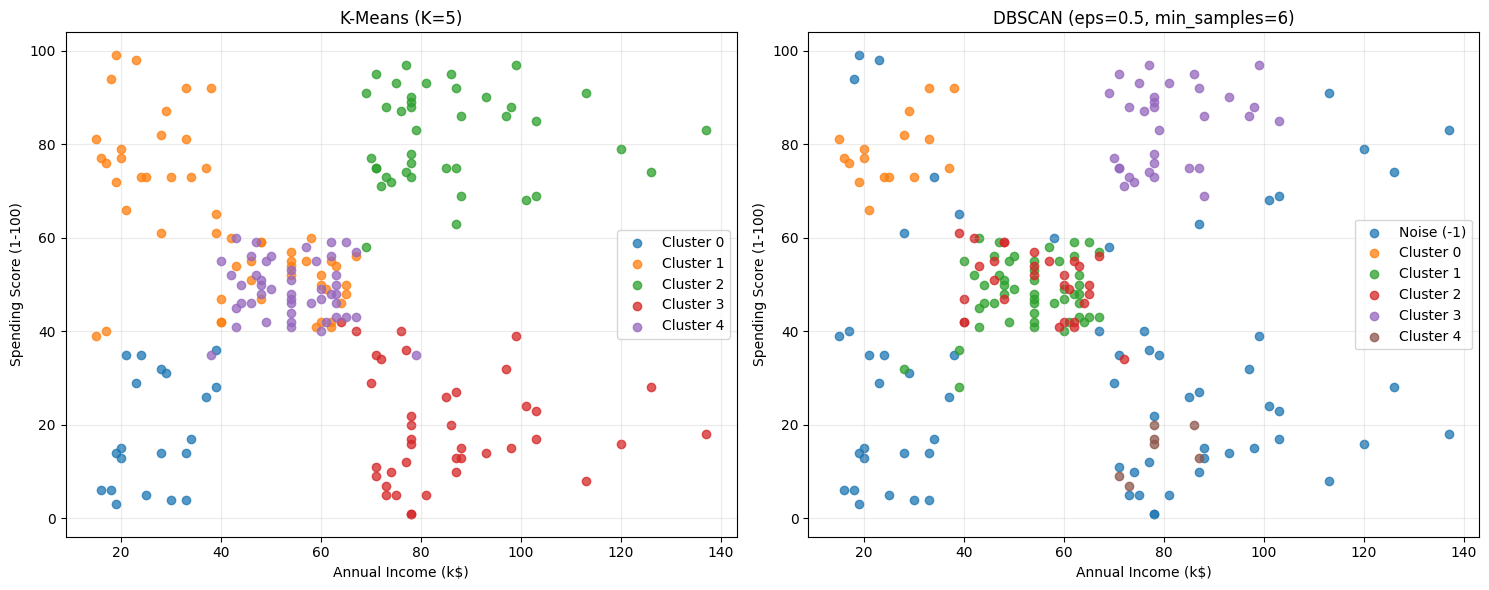

In [13]:
 fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# K-Means plot
for cluster in sorted(df["KMeans_Cluster"].unique()):
    subset = df[df["KMeans_Cluster"] == cluster]
    axes[0].scatter(
        subset["Annual Income (k$)"],
        subset["Spending Score (1-100)"],
        label=f"Cluster {cluster}",
        alpha=0.75
    )

axes[0].set_title("K-Means (K=5)")
axes[0].set_xlabel("Annual Income (k$)")
axes[0].set_ylabel("Spending Score (1-100)")
axes[0].legend()
axes[0].grid(alpha=0.25)

# DBSCAN plot, eps=0.5
for cluster in sorted(df["DBSCAN_eps_05"].unique()):
    subset = df[df["DBSCAN_eps_05"] == cluster]
    label = "Noise (-1)" if cluster == -1 else f"Cluster {cluster}"

    axes[1].scatter(
        subset["Annual Income (k$)"],
        subset["Spending Score (1-100)"],
        label=label,
        alpha=0.75
    )

axes[1].set_title("DBSCAN (eps=0.5, min_samples=6)")
axes[1].set_xlabel("Annual Income (k$)")
axes[1].set_ylabel("Spending Score (1-100)")
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()


In [14]:
digits_zip = DATA / "optical_recognition_handwritten_digits.zip"

with zipfile.ZipFile(digits_zip, "r") as z:
    print("Files inside ZIP:")
    for name in z.namelist():
        print(name)

Files inside ZIP:
lab06-optical_recognition_handwritten_digits/
lab06-optical_recognition_handwritten_digits/optdigits-orig.cv.Z
lab06-optical_recognition_handwritten_digits/optdigits-orig.names
lab06-optical_recognition_handwritten_digits/optdigits-orig.tra.Z
lab06-optical_recognition_handwritten_digits/optdigits-orig.wdep.Z
lab06-optical_recognition_handwritten_digits/optdigits-orig.windep.Z
lab06-optical_recognition_handwritten_digits/optdigits.names
lab06-optical_recognition_handwritten_digits/optdigits.tes
lab06-optical_recognition_handwritten_digits/optdigits.tra
lab06-optical_recognition_handwritten_digits/readme.txt


In [15]:
# Read the training and test files directly from the ZIP
with zipfile.ZipFile(digits_zip, "r") as z:
    train_file = (
        "lab06-optical_recognition_handwritten_digits/optdigits.tra"
    )
    test_file = (
        "lab06-optical_recognition_handwritten_digits/optdigits.tes"
    )

    train_digits = pd.read_csv(z.open(train_file), header=None)
    test_digits = pd.read_csv(z.open(test_file), header=None)

# Separate pixel features and labels
X_train = train_digits.iloc[:, :64].astype(float) / 16.0
y_train = train_digits.iloc[:, 64].astype(int)

X_test = test_digits.iloc[:, :64].astype(float) / 16.0
y_test = test_digits.iloc[:, 64].astype(int)

print("Training features:", X_train.shape)
print("Training labels:", y_train.shape)
print("Test features:", X_test.shape)
print("Test labels:", y_test.shape)

print("\nTraining digit counts:")
print(y_train.value_counts().sort_index())

print("\nPixel value range after scaling:")
print("Minimum:", X_train.min().min())
print("Maximum:", X_train.max().max())


Training features: (3823, 64)
Training labels: (3823,)
Test features: (1797, 64)
Test labels: (1797,)

Training digit counts:
64
0    376
1    389
2    380
3    389
4    387
5    376
6    377
7    387
8    380
9    382
Name: count, dtype: int64

Pixel value range after scaling:
Minimum: 0.0
Maximum: 1.0


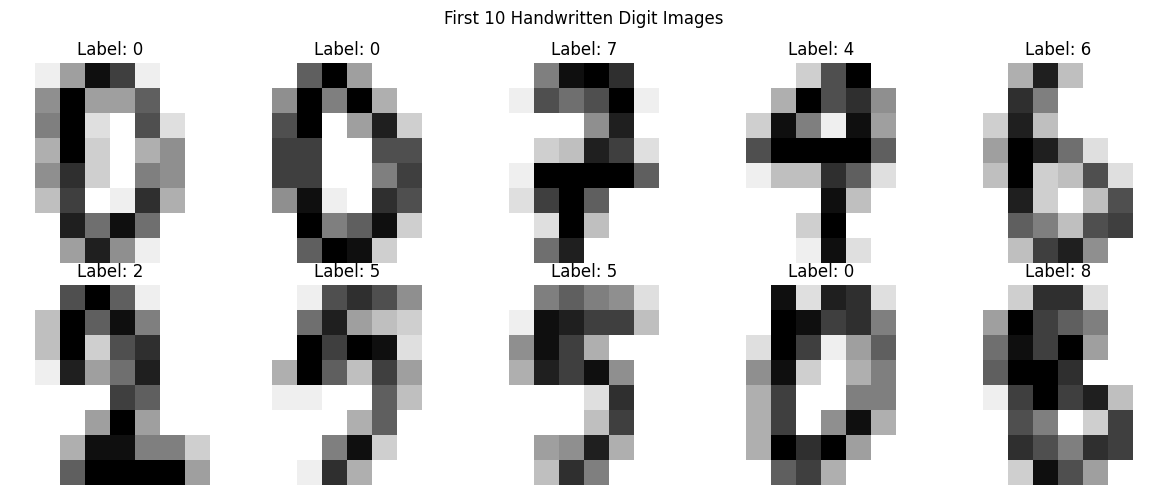

In [16]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    image = X_train.iloc[i].to_numpy().reshape(8, 8)

    ax.imshow(image, cmap="gray_r", vmin=0, vmax=1)
    ax.set_title(f"Label: {y_train.iloc[i]}")
    ax.axis("off")

plt.suptitle("First 10 Handwritten Digit Images")
plt.tight_layout()
plt.show()


In [17]:
# Split the official training data
X_dev, X_val, y_dev, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.25,
    random_state=42,
    stratify=y_train
)

print("Development set:", X_dev.shape)
print("Validation set:", X_val.shape)

# Train baseline Logistic Regression using all 64 pixels
baseline_model = LogisticRegression(max_iter=2000)
baseline_model.fit(X_dev, y_dev)

# Evaluate on validation data
baseline_predictions = baseline_model.predict(X_val)
baseline_accuracy = accuracy_score(y_val, baseline_predictions)

print("\nBaseline Logistic Regression (64 pixels)")
print("Validation accuracy:", round(baseline_accuracy, 4))

Development set: (2867, 64)
Validation set: (956, 64)

Baseline Logistic Regression (64 pixels)
Validation accuracy: 0.955


In [18]:
variance_levels = [0.90, 0.95, 0.99]
pca_results = []

for variance in variance_levels:
    pca_model = Pipeline([
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=variance)),
        ("classifier", LogisticRegression(max_iter=2000))
    ])

    pca_model.fit(X_dev, y_dev)
    predictions = pca_model.predict(X_val)
    accuracy = accuracy_score(y_val, predictions)

    n_components = pca_model.named_steps["pca"].n_components_

    pca_results.append({
        "Retained Variance": variance,
        "Number of Components": n_components,
        "Validation Accuracy": accuracy
    })

pca_results_df = pd.DataFrame(pca_results)

print("Baseline accuracy (64 original pixels):", round(baseline_accuracy, 4))
display(pca_results_df.round(4))

Baseline accuracy (64 original pixels): 0.955


,Retained Variance,Number of Components,Validation Accuracy
0,0.90,32,0.9571
1,0.95,41,0.9540
2,0.99,55,0.9571


In [19]:
# Final PCA model: retain 95% variance
final_model = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=0.95)),
    ("classifier", LogisticRegression(max_iter=2000))
])

# Fit using all official training data
final_model.fit(X_train, y_train)

# Full-feature baseline
final_baseline = LogisticRegression(max_iter=2000)
final_baseline.fit(X_train, y_train)

# Evaluate on the official test set
pca_test_predictions = final_model.predict(X_test)
baseline_test_predictions = final_baseline.predict(X_test)

pca_test_accuracy = accuracy_score(y_test, pca_test_predictions)
baseline_test_accuracy = accuracy_score(y_test, baseline_test_predictions)

n_final_components = final_model.named_steps["pca"].n_components_
retained_variance = final_model.named_steps["pca"].explained_variance_ratio_.sum()

print("FINAL TEST RESULTS")
print("-" * 35)
print("Baseline components:", X_train.shape[1])
print("Baseline test accuracy:", round(baseline_test_accuracy, 4))
print()
print("PCA components:", n_final_components)
print("PCA retained variance:", round(retained_variance, 4))
print("PCA test accuracy:", round(pca_test_accuracy, 4))
print()
print(
    "Accuracy difference (PCA - baseline):",
    round(pca_test_accuracy - baseline_test_accuracy, 4)
)


FINAL TEST RESULTS
-----------------------------------
Baseline components: 64
Baseline test accuracy: 0.9477

PCA components: 41
PCA retained variance: 0.9506
PCA test accuracy: 0.9427

Accuracy difference (PCA - baseline): -0.005


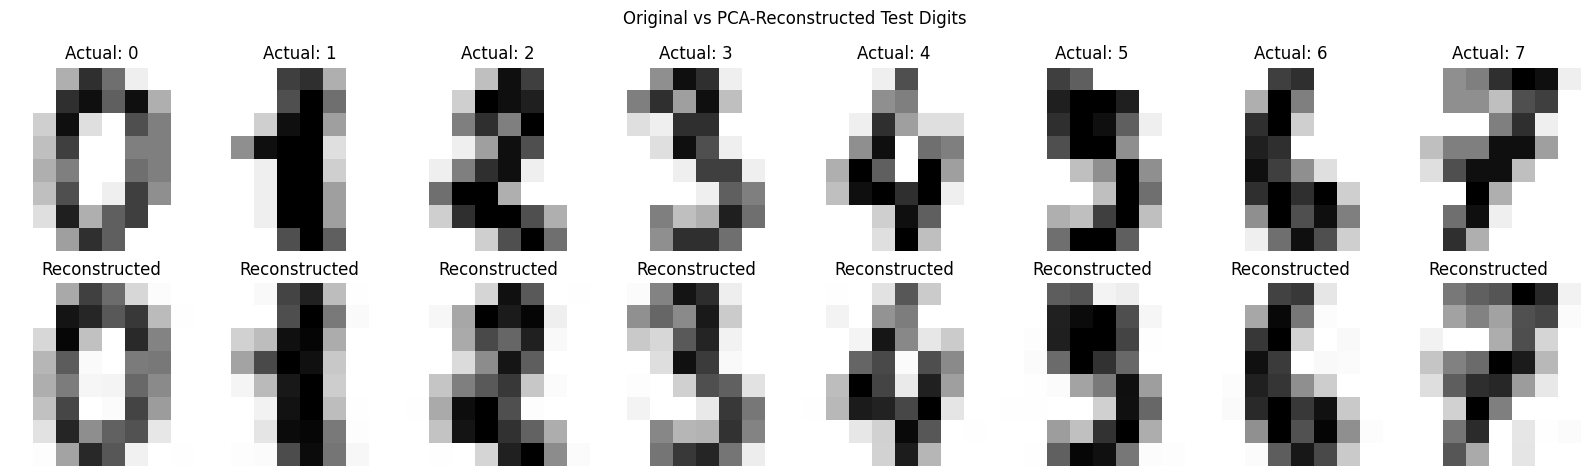

In [20]:
# Extract the fitted scaler and PCA transformer
scaler_final = final_model.named_steps["scaler"]
pca_final = final_model.named_steps["pca"]

# Transform and reconstruct the first 8 test images
X_test_first8 = X_test.iloc[:8]
X_scaled_first8 = scaler_final.transform(X_test_first8)

X_reconstructed_scaled = pca_final.inverse_transform(
    pca_final.transform(X_scaled_first8)
)

# Convert reconstructed pixels back to the original scaled pixel space
X_reconstructed = scaler_final.inverse_transform(
    X_reconstructed_scaled
)

# Plot original and reconstructed images
fig, axes = plt.subplots(2, 8, figsize=(16, 5))

for i in range(8):
    original = X_test_first8.iloc[i].to_numpy().reshape(8, 8)
    reconstructed = X_reconstructed[i].reshape(8, 8)

    axes[0, i].imshow(original, cmap="gray_r", vmin=0, vmax=1)
    axes[0, i].set_title(f"Actual: {y_test.iloc[i]}")
    axes[0, i].axis("off")

    axes[1, i].imshow(reconstructed, cmap="gray_r", vmin=0, vmax=1)
    axes[1, i].set_title("Reconstructed")
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Original", fontsize=11)
axes[1, 0].set_ylabel("PCA", fontsize=11)

plt.suptitle("Original vs PCA-Reconstructed Test Digits")
plt.tight_layout()
plt.show()

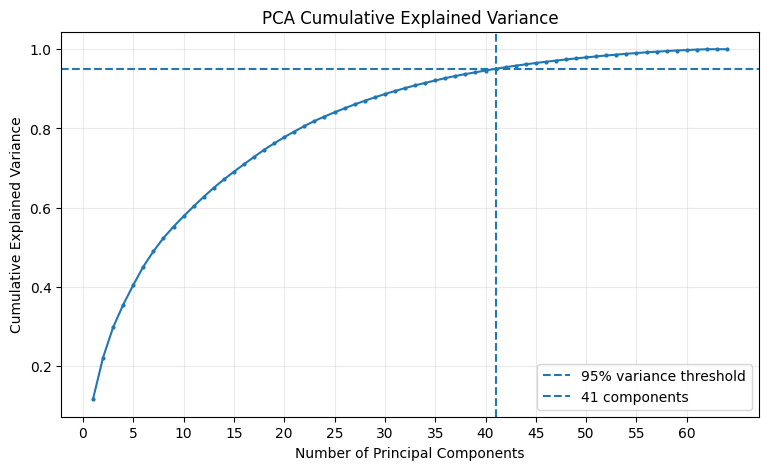

Components required for 95% variance: 41
Cumulative variance retained: 0.9506


In [21]:
# Fit PCA on training data only
scaler_variance = StandardScaler()
X_train_scaled = scaler_variance.fit_transform(X_train)

pca_variance = PCA(svd_solver="full")
pca_variance.fit(X_train_scaled)

cumulative_variance = np.cumsum(
    pca_variance.explained_variance_ratio_
)

components_95 = np.argmax(cumulative_variance >= 0.95) + 1

plt.figure(figsize=(9, 5))
plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker=".",
    markersize=4
)

plt.axhline(
    y=0.95,
    linestyle="--",
    label="95% variance threshold"
)

plt.axvline(
    x=components_95,
    linestyle="--",
    label=f"{components_95} components"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Cumulative Explained Variance")
plt.xticks(range(0, 65, 5))
plt.grid(alpha=0.25)
plt.legend()
plt.show()

print("Components required for 95% variance:", components_95)
print(
    "Cumulative variance retained:",
    round(cumulative_variance[components_95 - 1], 4)
)

In [22]:
# Save the complete trained PCA + Logistic Regression pipeline
model_path = MODELS / "digits_pca_logistic.joblib"

joblib.dump(final_model, model_path)

print("Model saved successfully!")
print("Location:", model_path)
print("File exists:", model_path.exists())


Model saved successfully!
Location: /content/UTP-MACHINE-LEARNING/models/digits_pca_logistic.joblib
File exists: True


In [23]:
# Reload the saved model
loaded_model = joblib.load(model_path)

# Predict the first five official test samples
sample_predictions = loaded_model.predict(X_test.iloc[:5])
actual_labels = y_test.iloc[:5].to_numpy()

print("Predicted labels:", sample_predictions.tolist())
print("Actual labels:   ", actual_labels.tolist())

# Verify that reloaded predictions match the original model
original_predictions = final_model.predict(X_test.iloc[:5])

print(
    "Predictions identical:",
    np.array_equal(sample_predictions, original_predictions)
)

Predicted labels: [0, 1, 1, 3, 4]
Actual labels:    [0, 1, 2, 3, 4]
Predictions identical: True


In [24]:
# Check the experiment notebooks currently in the repository
experiment_dir = PROJECT_ROOT / "all_experiments"

print("Experiment directory exists:", experiment_dir.exists())

if experiment_dir.exists():
    for file in sorted(experiment_dir.iterdir()):
        print(file.name)

Experiment directory exists: True
Lab01_feature_engineering.ipynb
Lab02_supervised_learning.ipynb
lab03_model_families.ipynb
